--- VERIFICHE MATRICE Cz ---
La matrice è simmetrica? {is_symmetric}
La diagonale è positiva? True
Gli autovalori sono non negativi? True
Autovalori: [0.0001     0.0001     0.00017422 0.00217478]

--- MATRICE DI CORRELAZIONE ---
[[ 1.   -0.65  0.    0.  ]
 [-0.65  1.    0.    0.  ]
 [ 0.    0.    1.    0.  ]
 [ 0.    0.    0.    1.  ]]


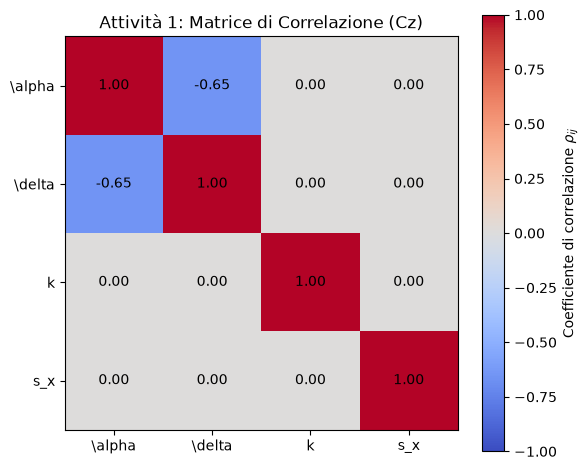

In [3]:
import numpy as np
import matplotlib.pyplot as plt 

#Definizione parametri dati
alpha_hat = 0.910
u_alpha = 0.018

delta_hat = 5.180
u_delta = 0.045

#Fattori di calibrazione k e s_x
k_hat = 1.000
u_k = 0.010

sx_hat = 1.000
u_sx = 0.010

#Coefficiente di correlazione tra alpha e delta
rho_alpha_delta = -0.65

#Covarianza
cov_alpha_delta = rho_alpha_delta * u_alpha * u_delta

#Costruzione matrice
C_z = np.array
C_z = np.array([
    [u_alpha**2,       cov_alpha_delta, 0.0,     0.0],
    [cov_alpha_delta,  u_delta**2,      0.0,     0.0],
    [0.0,              0.0,             u_k**2,  0.0],
    [0.0,              0.0,             0.0,     u_sx**2]
])

#Verifica della simmetria
is_symmetric = np.allclose(C_z, C_z.T)

#Verifica diagonale positiva
has_positive_diag = np.all(np.diagonal(C_z) > 0)

#Verifica autovalori non negativi
autovalori = np.linalg.eigvalsh(C_z)
has_nonnegative_eig = np.all(autovalori >= 0)

print("--- VERIFICHE MATRICE Cz ---")
print("La matrice è simmetrica? {is_symmetric}")
print(f"La diagonale è positiva? {has_positive_diag}")
print(f"Gli autovalori sono non negativi? {has_nonnegative_eig}")
print(f"Autovalori: {autovalori}")

#Calcolo della matrice di correlazione a partiria da Cz
# Formula: rho_ij = C_ij / sqrt(C_ii * C_jj)
perr_z = np.sqrt(np.diagonal(C_z))
corr_matrix_z = C_z / np.outer(perr_z, perr_z)

#Nomi delle variabili per i grafici e gli assi
var_names = [r"\alpha", r"\delta", "k", "s_x"]

print("\n--- MATRICE DI CORRELAZIONE ---")
print(corr_matrix_z)

#Visualizzazione con mappa di colore (Heatmap)
plt.figure(figsize=(6, 5))
plt.imshow(corr_matrix_z, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label=r"Coefficiente di correlazione $\rho_{ij}$")
plt.xticks(range(4), var_names)
plt.yticks(range(4), var_names)
plt.title("Attività 1: Matrice di Correlazione (Cz)")

#Annotare i valori numerici all'interno delle celle
for i in range(4):
    for j in range(4):
        plt.text(
            j, i, f"{corr_matrix_z[i, j]:.2f}", 
            ha="center", va="center", color="black"
        )

plt.tight_layout()
plt.show()


In [5]:

# ATTIVITÀ 2: Propagazione analitica (Jacobiano)

#Calcolo dei valori centrali delle grandezze derivate a, d, q
a_val = alpha_hat / (k_hat * sx_hat)
d_val = delta_hat / (k_hat * sx_hat)
q_val = d_val / a_val  #equivalente a delta_hat / alpha_hat

print("--- VALORI CENTRALI DERIVATI ---")
print(f"a = {a_val:.4f} mm")
print(f"d = {d_val:.4f} mm")
print(f"q = {q_val:.4f}")

#Definizione della matrice Jacobiana J (3x4)
# Righe: derivate rispetto a [a, d, q]
# Colonne: derivate rispetto a [alpha, delta, k, sx]
# J = [ [da/d_alpha, da/d_delta, da/dk, da/dsx],
#       [dd/d_alpha, dd/d_delta, dd/dk, dd/dsx],
#       [dq/d_alpha, dq/d_delta, dq/dk, dq/dsx] ]

#Singoli elementi del Jacobiano nel punto nominale:
# da/d_alpha = 1 / (k * sx)
# da/d_delta = 0
# da/dk = - alpha / (k^2 * sx)
# da/dsx = - alpha / (k * sx^2)

J = np.array([
    [1.0 / (k_hat * sx_hat),  0.0,  -alpha_hat / (k_hat**2 * sx_hat),  -alpha_hat / (k_hat * sx_hat**2)],
    [0.0,  1.0 / (k_hat * sx_hat),  -delta_hat / (k_hat**2 * sx_hat),  -delta_hat / (k_hat * sx_hat**2)],
    [-delta_hat / (alpha_hat**2),  1.0 / alpha_hat,  0.0,  0.0]
])

#Propagazione lineare della covarianza
C_g = J @ C_z @ J.T

#Estrazione delle incertezze standard (incertezze marginali)
perr_g = np.sqrt(np.diagonal(C_g))
u_a, u_d, u_q = perr_g

print("\n--- RISULTATI PROPAGAZIONE ANALITICA ---")
print(f"a = {a_val:.4f} ± {u_a:.4f} mm")
print(f"d = {d_val:.4f} ± {u_d:.4f} mm")
print(f"q = {q_val:.4f} ± {u_q:.4f}")

#Verifica della formula analitica per u(q) richiesta dalla guida:
rel_var_q_formula = (u_delta / delta_hat)**2 + (u_alpha / alpha_hat)**2 - (2 * cov_alpha_delta) / (alpha_hat * delta_hat)
u_q_verifica = q_val * np.sqrt(rel_var_q_formula)
print(f"\nVerifica incertezza q tramite formula esplicita: {u_q_verifica:.4f} (deve coincidere con {u_q:.4f})")

--- VALORI CENTRALI DERIVATI ---
a = 0.9100 mm
d = 5.1800 mm
q = 5.6923

--- RISULTATI PROPAGAZIONE ANALITICA ---
a = 0.9100 ± 0.0221 mm
d = 5.1800 ± 0.0860 mm
q = 5.6923 ± 0.1495

Verifica incertezza q tramite formula esplicita: 0.1495 (deve coincidere con 0.1495)


--- RISULTATI MONTE CARLO (M = 100.000) ---
a -> Media: 0.9102, Dev.Std: 0.0222, Mediana: 0.9099, [16°, 84°]: [0.8883, 0.9323]
d -> Media: 5.1810, Dev.Std: 0.0861, Mediana: 5.1800, [16°, 84°]: [5.0953, 5.2668]
q -> Media: 5.6949, Dev.Std: 0.1500, Mediana: 5.6923, [16°, 84°]: [5.5457, 5.8436]


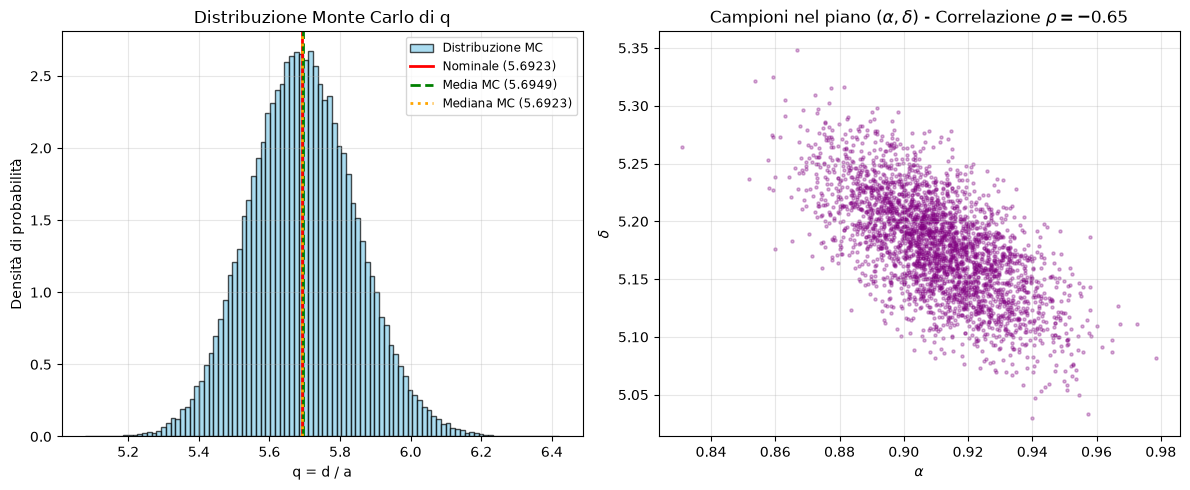

In [6]:
# ATTIVITÀ 3: Propagazione Monte Carlo correlata
#Configurazione del generatore casuale con il seed richiesto dalla guida
rng = np.random.default_rng(20261003)

#Vettore dei valori medi 
media_input = np.array([alpha_hat, delta_hat, k_hat, sx_hat])

#Numero di campioni Monte Carlo
M = 100000

#Generazione dei campioni gaussiani multivariati correlati (4 x M)
campioni_z = rng.multivariate_normal(
    mean=media_input,
    cov=C_z,
    size=M
)

#Estrazione dei singoli vettori di campioni per comodità
alpha_mc = campioni_z[:, 0]
delta_mc = campioni_z[:, 1]
k_mc = campioni_z[:, 2]
sx_mc = campioni_z[:, 3]

#Calcolo delle grandezze derivate a, d, q per tutti i 100.000 campioni
a_mc = alpha_mc / (k_mc * sx_mc)
d_mc = delta_mc / (k_mc * sx_mc)
q_mc = d_mc / a_mc  # oppure delta_mc / alpha_mc

#Funzione di supporto per estrarre le statistiche richieste dalla guida
def statistiche_mc(array):
    media = np.mean(array)
    std = np.std(array, ddof=1)  # deviazione standard con dof=1
    mediana = np.median(array)
    p16, p84 = np.percentile(array, [16, 84])
    return media, std, mediana, p16, p84

m_a, s_a, med_a, p16_a, p84_a = statistiche_mc(a_mc)
m_d, s_d, med_d, p16_d, p84_d = statistiche_mc(d_mc)
m_q, s_q, med_q, p16_q, p84_q = statistiche_mc(q_mc)

print("--- RISULTATI MONTE CARLO (M = 100.000) ---")
print(f"a -> Media: {m_a:.4f}, Dev.Std: {s_a:.4f}, Mediana: {med_a:.4f}, [16°, 84°]: [{p16_a:.4f}, {p84_a:.4f}]")
print(f"d -> Media: {m_d:.4f}, Dev.Std: {s_d:.4f}, Mediana: {med_d:.4f}, [16°, 84°]: [{p16_d:.4f}, {p84_d:.4f}]")
print(f"q -> Media: {m_q:.4f}, Dev.Std: {s_q:.4f}, Mediana: {med_q:.4f}, [16°, 84°]: [{p16_q:.4f}, {p84_q:.4f}]")

#Rappresentazione grafica: Istogramma di q e Scatter plot di alpha vs delta
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

#Istogramma di q con indicatori (media, mediana, valore nominale)
ax1.hist(q_mc, bins=100, density=True, color='skyblue', edgecolor='black', alpha=0.7, label='Distribuzione MC')
ax1.axvline(q_val, color='red', linestyle='-', linewidth=2, label=f'Nominale ({q_val:.4f})')
ax1.axvline(m_q, color='green', linestyle='--', linewidth=2, label=f'Media MC ({m_q:.4f})')
ax1.axvline(med_q, color='orange', linestyle=':', linewidth=2, label=f'Mediana MC ({med_q:.4f})')
ax1.set_xlabel('q = d / a')
ax1.set_ylabel('Densità di probabilità')
ax1.set_title('Distribuzione Monte Carlo di q')
ax1.legend(fontsize='small')
ax1.grid(True, alpha=0.3)

#Scatter plot di un sottoinsieme di campioni nel piano (alpha, delta) per vedere la correlazione negativa (-0.65)
#Prendiamo ad esempio 3000 campioni per non appesantire il grafico
idx = rng.choice(M, size=3000, replace=False)
ax2.scatter(alpha_mc[idx], delta_mc[idx], alpha=0.3, s=5, color='purple')
ax2.set_xlabel(r'$\alpha$')
ax2.set_ylabel(r'$\delta$')
ax2.set_title(r'Campioni nel piano ($\alpha, \delta$) - Correlazione $\rho = -0.65$')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

--- CONFRONTO: CON CORRELAZIONE VS SENZA CORRELAZIONE ---
Incertezza analitica su a -> Con corr: 0.0221 | Senza corr: 0.0221
Incertezza analitica su d -> Con corr: 0.0860 | Senza corr: 0.0860
Incertezza analitica su q -> Con corr: 0.1495 | Senza corr: 0.1230
-------------------------------------------------------
Dev. Std. Monte Carlo su a -> Con corr: 0.0222 | Senza corr: 0.0222
Dev. Std. Monte Carlo su d -> Con corr: 0.0861 | Senza corr: 0.0861
Dev. Std. Monte Carlo su q -> Con corr: 0.1500 | Senza corr: 0.1233


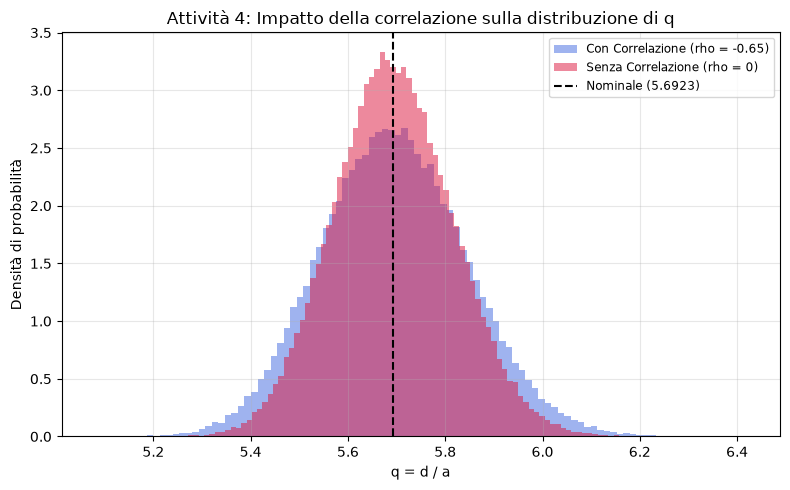

In [7]:
# ATTIVITÀ 4: Effetto delle correlazioni (rho = 0)

#Creiamo una nuova matrice di covarianza Cz_senza_corr azzerando la covarianza tra alpha e delta
cov_zero = 0.0

C_z_uncorr = np.array([
    [u_alpha**2,       cov_zero,    0.0,     0.0],
    [cov_zero,         u_delta**2,  0.0,     0.0],
    [0.0,              0.0,         u_k**2,  0.0],
    [0.0,              0.0,         0.0,     u_sx**2]
])

#Ripetizione della propagazione analitica con C_z_uncorr
C_g_uncorr = J @ C_z_uncorr @ J.T
perr_g_uncorr = np.sqrt(np.diagonal(C_g_uncorr))
u_a_uncorr, u_d_uncorr, u_q_uncorr = perr_g_uncorr

#Ripetizione del Monte Carlo con C_z_uncorr (usando lo stesso seed per equità)
rng_uncorr = np.random.default_rng(20261003)
campioni_z_uncorr = rng_uncorr.multivariate_normal(
    mean=media_input,
    cov=C_z_uncorr,
    size=M
)

a_mc_unc = campioni_z_uncorr[:, 0] / (campioni_z_uncorr[:, 2] * campioni_z_uncorr[:, 3])
d_mc_unc = campioni_z_uncorr[:, 1] / (campioni_z_uncorr[:, 2] * campioni_z_uncorr[:, 3])
q_mc_unc = d_mc_unc / a_mc_unc

s_a_unc = np.std(a_mc_unc, ddof=1)
s_d_unc = np.std(d_mc_unc, ddof=1)
s_q_unc = np.std(q_mc_unc, ddof=1)

#Stampiamo il confronto diretto
print("--- CONFRONTO: CON CORRELAZIONE VS SENZA CORRELAZIONE ---")
print(f"Incertezza analitica su a -> Con corr: {u_a:.4f} | Senza corr: {u_a_uncorr:.4f}")
print(f"Incertezza analitica su d -> Con corr: {u_d:.4f} | Senza corr: {u_d_uncorr:.4f}")
print(f"Incertezza analitica su q -> Con corr: {u_q:.4f} | Senza corr: {u_q_uncorr:.4f}")
print("-" * 55)
print(f"Dev. Std. Monte Carlo su a -> Con corr: {s_a:.4f} | Senza corr: {s_a_unc:.4f}")
print(f"Dev. Std. Monte Carlo su d -> Con corr: {s_d:.4f} | Senza corr: {s_d_unc:.4f}")
print(f"Dev. Std. Monte Carlo su q -> Con corr: {s_q:.4f} | Senza corr: {s_q_unc:.4f}")

#Grafico di confronto visivo delle distribuzioni di q (Con vs Senza correlazione)
plt.figure(figsize=(8, 5))
plt.hist(q_mc, bins=100, density=True, alpha=0.5, color='royalblue', label='Con Correlazione (rho = -0.65)')
plt.hist(q_mc_unc, bins=100, density=True, alpha=0.5, color='crimson', label='Senza Correlazione (rho = 0)')
plt.axvline(q_val, color='black', linestyle='--', label=f'Nominale ({q_val:.4f})')
plt.xlabel('q = d / a')
plt.ylabel('Densità di probabilità')
plt.title('Attività 4: Impatto della correlazione sulla distribuzione di q')
plt.legend(fontsize='small')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

--- MAPPA DEI CONTRIBUTI PERCENTUALI ALLA VARIANZA ---
Per 'a' -> Fit: 66.2% | Calibrazione k: 16.9% | Calibrazione sx: 16.9%
Per 'd' -> Fit: 27.4% | Calibrazione k: 36.3% | Calibrazione sx: 36.3%
Per 'q' -> Fit: 100.0% | Calibrazione k: 0.0% | Calibrazione sx: 0.0%


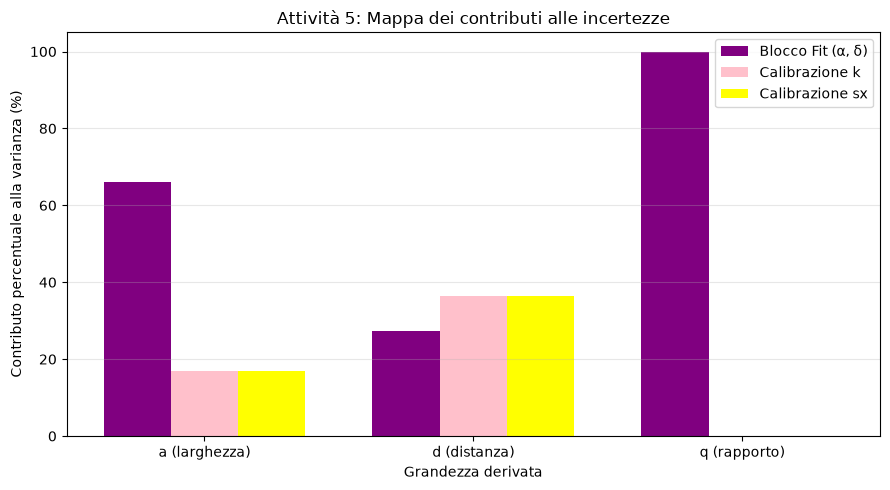

In [11]:
# ATTIVITÀ 5: Mappa dei contributi 

# Calcoliamo la varianza totale (tramite il metodo analitico con C_z completa)
# u_a^2, u_d^2, u_q^2 : quadrati delle incertezze totali
var_tot_a = C_g[0, 0]
var_tot_d = C_g[1, 1]
var_tot_q = C_g[2, 2]

# Contributo 1: Solo il blocco del fit (alpha, delta attivi; k e sx fissi senza errore)
C_z_fit = np.array([
    [u_alpha**2,       cov_alpha_delta, 0.0, 0.0],
    [cov_alpha_delta,  u_delta**2,      0.0, 0.0],
    [0.0,              0.0,             0.0, 0.0],
    [0.0,              0.0,             0.0, 0.0]
])
C_g_fit = J @ C_z_fit @ J.T
var_fit_a = C_g_fit[0, 0]
var_fit_d = C_g_fit[1, 1]
var_fit_q = C_g_fit[2, 2]

# Contributo 2: Solo la calibrazione k (solo u_k attivo)
C_z_k = np.array([
    [0.0, 0.0, 0.0,     0.0],
    [0.0, 0.0, 0.0,     0.0],
    [0.0, 0.0, u_k**2,  0.0],
    [0.0, 0.0, 0.0,     0.0]
])
C_g_k = J @ C_z_k @ J.T
var_k_a = C_g_k[0, 0]
var_k_d = C_g_k[1, 1]
var_k_q = C_g_k[2, 2]

# Contributo 3: Solo la calibrazione sx (solo u_sx attivo)
C_z_sx = np.array([
    [0.0, 0.0, 0.0, 0.0   ],
    [0.0, 0.0, 0.0, 0.0   ],
    [0.0, 0.0, 0.0, 0.0   ],
    [0.0, 0.0, 0.0, u_sx**2]
])
C_g_sx = J @ C_z_sx @ J.T
var_sx_a = C_g_sx[0, 0]
var_sx_d = C_g_sx[1, 1]
var_sx_q = C_g_sx[2, 2]

# Calcolo delle frazioni percentuali F_j(g)
def frazioni(v_fit, v_k, v_sx, v_tot):
    return (v_fit / v_tot) * 100, (v_k / v_tot) * 100, (v_sx / v_tot) * 100

f_fit_a, f_k_a, f_sx_a = frazioni(var_fit_a, var_k_a, var_sx_a, var_tot_a)
f_fit_d, f_k_d, f_sx_d = frazioni(var_fit_d, var_k_d, var_sx_d, var_tot_d)
f_fit_q, f_k_q, f_sx_q = frazioni(var_fit_q, var_k_q, var_sx_q, var_tot_q)

print("--- MAPPA DEI CONTRIBUTI PERCENTUALI ALLA VARIANZA ---")
print(f"Per 'a' -> Fit: {f_fit_a:.1f}% | Calibrazione k: {f_k_a:.1f}% | Calibrazione sx: {f_sx_a:.1f}%")
print(f"Per 'd' -> Fit: {f_fit_d:.1f}% | Calibrazione k: {f_k_d:.1f}% | Calibrazione sx: {f_sx_d:.1f}%")
print(f"Per 'q' -> Fit: {f_fit_q:.1f}% | Calibrazione k: {f_k_q:.1f}% | Calibrazione sx: {f_sx_q:.1f}%")

# Grafico a barre raggruppate delle frazioni percentuali
grandezze = ['a (larghezza)', 'd (distanza)', 'q (rapporto)']
fit_vals = [f_fit_a, f_fit_d, f_fit_q]
k_vals = [f_k_a, f_k_d, f_k_q]
sx_vals = [f_sx_a, f_sx_d, f_sx_q]

x_pos = np.arange(len(grandezze))
width = 0.25

plt.figure(figsize=(9, 5))
plt.bar(x_pos - width, fit_vals, width, label='Blocco Fit (α, δ)', color='purple')
plt.bar(x_pos, k_vals, width, label='Calibrazione k', color='pink')
plt.bar(x_pos + width, sx_vals, width, label='Calibrazione sx', color='yellow')

plt.xlabel('Grandezza derivata')
plt.ylabel('Contributo percentuale alla varianza (%)')
plt.title('Attività 5: Mappa dei contributi alle incertezze')
plt.xticks(x_pos, grandezze)
plt.legend()
plt.ylim(0, 105)
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
# ATTIVITÀ 6: Controlli di stabilità e Scenari

def calcola_incertezze_scenario(Cz_scenario):
    #Propagazione analitica con la matrice di covarianza dello scenario
    C_g_scen = J @ Cz_scenario @ J.T
    u_a_s, u_d_s, u_q_s = np.sqrt(np.diagonal(C_g_scen))
    return u_a_s, u_d_s, u_q_s

#Nominale
ua_nom, ud_nom, uq_nom = calcola_incertezze_scenario(C_z)

#Correlazione ignorata (rho = 0)
ua_corr0, ud_corr0, uq_corr0 = calcola_incertezze_scenario(C_z_uncorr)

#Calibrazione di k migliorata 
uk_2 = (u_k / 2.0)**2
C_z_k2 = C_z.copy()
C_z_k2[2, 2] = uk_2
ua_k2, ud_k2, uq_k2 = calcola_incertezze_scenario(C_z_k2)

#Calibrazione di sx migliorata 
usx_2 = (u_sx / 2.0)**2
C_z_sx2 = C_z.copy()
C_z_sx2[3, 3] = usx_2
ua_sx2, ud_sx2, uq_sx2 = calcola_incertezze_scenario(C_z_sx2)

#Statistica del fit migliorata
C_z_fit2 = C_z.copy()
C_z_fit2[0:2, 0:2] = C_z[0:2, 0:2] / 4.0
ua_fit2, ud_fit2, uq_fit2 = calcola_incertezze_scenario(C_z_fit2)

#Tabella riassuntiva pulita
print("--- TABELLA COMPARATIVA DEGLI SCENARI DI STABILITÀ ---")
print(f"{'Scenario':<35} | {'u(a) [mm]':<12} | {'u(d) [mm]':<12} | {'u(q)':<12}")
print("-" * 78)
print(f"{'1. Nominale':<35} | {ua_nom:<12.5f} | {ud_nom:<12.5f} | {uq_nom:<12.5f}")
print(f"{'2. Correlazione ignorata (rho=0)':<35} | {ua_corr0:<12.5f} | {ud_corr0:<12.5f} | {uq_corr0:<12.5f}")
print(f"{'3. Calibrazione k migliorata (u_k/2)':<35} | {ua_k2:<12.5f} | {ud_k2:<12.5f} | {uq_k2:<12.5f}")
print(f"{'4. Calibrazione sx migliorata (u_sx/2)':<35} | {ua_sx2:<12.5f} | {ud_sx2:<12.5f} | {uq_sx2:<12.5f}")
print(f"{'5. Statistica fit migliorata (fit/2)':<35} | {ua_fit2:<12.5f} | {ud_fit2:<12.5f} | {uq_fit2:<12.5f}")

--- TABELLA COMPARATIVA DEGLI SCENARI DI STABILITÀ ---
Scenario                            | u(a) [mm]    | u(d) [mm]    | u(q)        
------------------------------------------------------------------------------
1. Nominale                         | 0.02213      | 0.08597      | 0.14954     
2. Correlazione ignorata (rho=0)    | 0.02213      | 0.08597      | 0.12298     
3. Calibrazione k migliorata (u_k/2) | 0.02068      | 0.07334      | 0.14954     
4. Calibrazione sx migliorata (u_sx/2) | 0.02068      | 0.07334      | 0.14954     
5. Statistica fit migliorata (fit/2) | 0.01570      | 0.07663      | 0.07477     
